
### My Question
When rolling a fair 6-sided die once, what is the probability of rolling a number greater than 4 (a 5 or a 6)?
Type of study: Simulation study (estimating a probability from simulated data and comparing it to the theoretical probability)


### My Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(42)

rolls = pd.DataFrame({'roll_number': np.arange(1, 1001), 'outcome': rng.integers(1, 7, size=1000)})
rolls['in_event'] = rolls['outcome'] > 4
rolls.head()

,roll_number,outcome,in_event
0,1,1,False
1,2,5,True
2,3,4,False
3,4,3,False
4,5,3,False


In [2]:
empirical_p = rolls['in_event'].mean()

sample_space = [1, 2, 3, 4, 5, 6]
theoretical_p = len([x for x in sample_space if x > 4]) / len(sample_space)

print(f'Empirical P(roll > 4)   = {empirical_p:.3f}')
print(f'Theoretical P(roll > 4) = {theoretical_p:.3f}')

Empirical P(roll > 4)   = 0.336
Theoretical P(roll > 4) = 0.333


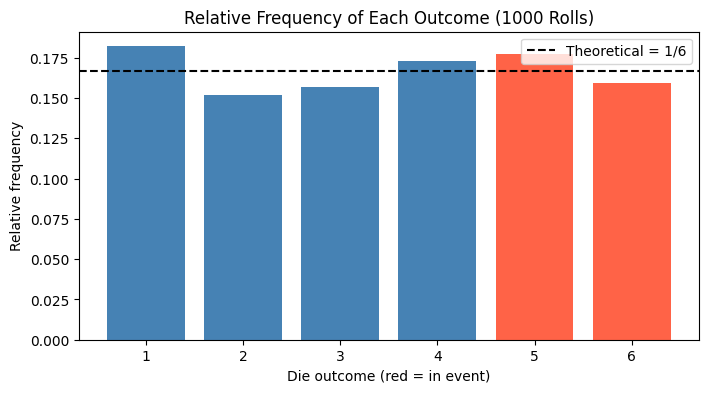

In [ ]:
freq = rolls['outcome'].value_counts(normalize=True).sort_index()
colors = ['tomato' if o > 4 else 'steelblue' for o in freq.index]
plt.figure(figsize=(8, 4))
plt.bar(freq.index, freq.values, color=colors)
plt.axhline(1/6, color='black', linestyle='--', label='Theoretical = 1/6')
plt.title('Relative Frequency of Each Outcome (1000 Rolls)')
plt.xlabel('Die outcome (red = in event)'); plt.ylabel('Relative frequency')
plt.legend(); plt.show()

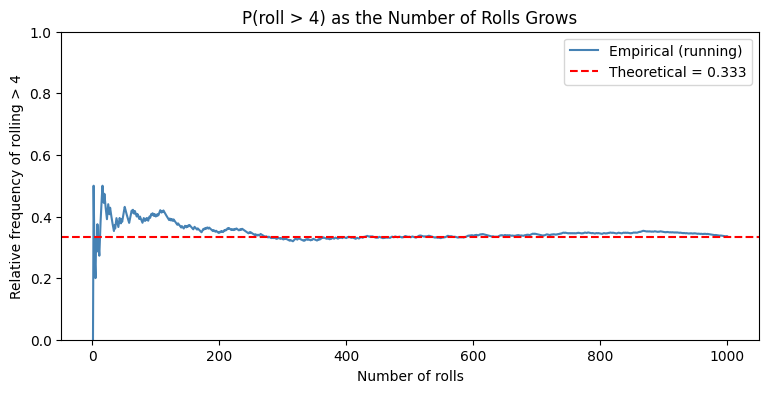

In [ ]:
rolls['running_freq'] = rolls['in_event'].cumsum() / rolls['roll_number']
plt.figure(figsize=(9, 4))
sns.lineplot(data=rolls, x='roll_number', y='running_freq', color='steelblue', label='Empirical (running)')
plt.axhline(theoretical_p, color='red', linestyle='--', label=f'Theoretical = {theoretical_p:.3f}')
plt.title('P(roll > 4) as the Number of Rolls Grows')
plt.xlabel('Number of rolls'); plt.ylabel('Relative frequency of rolling > 4')
plt.ylim(0, 1); plt.legend(); plt.show()

### Conclusion
A probability of 1/3 (or ≈0.333) exists for rolling a die to have a result of a number above 4. With 1,000 rolls of the die, the probability that was recorded empirically was 0.336, which is close to the expected results. From the graphs, one can observe that 5 and 6 make one-third of all the results recorded.